In [3]:
!mamba install pandas numpy matplotlib seaborn

mambajs 0.21.1

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.8467000000476836 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.0.3    np23py313h1e705a5_0  emscripten-forge-4x
+ patsy          1.0.2    py313h1804a44_3      emscripten-forge-4x
+ python-tzdata  2026.2   pyhd8ed1ab_0         conda-forge
+ seaborn        0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base   0.13.2   pyhd8ed1ab_3         conda-forge
+ statsmodels    0.14.6   np23py313hd8db738_2  emscripten-forge-4x
- pip            26.1.2   pyh145f28c_0         conda-forge


In [4]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('flawed_dataset.csv')
df.head()

,ID,Name,Age,Gender,Email,Join_Date,Salary,Department,Feedback_Score,Left_Company
0,353,BOB,999.0,f,NaN,2021-01-01,1000000.0,NaN,2.5,N
1,690,NaN,-5.0,FEMALE,NaN,NaN,33020.0,NaN,10.0,No
2,486,eve,-5.0,F,invalid-email,2020-05-30,NaN,hr,NaN,NaN
3,389,Alice,-5.0,male,NaN,2021-01-01,1000000.0,FIN,NaN,0
4,32,BOB,-5.0,m,user131@example.com,2021-01-01,NaN,NaN,NaN,Y


In [6]:
df.shape

(1050, 10)

In [7]:
initial_info = df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID              1050 non-null   int64  
 1   Name            886 non-null    str    
 2   Age             792 non-null    float64
 3   Gender          905 non-null    str    
 4   Email           527 non-null    str    
 5   Join_Date       610 non-null    str    
 6   Salary          774 non-null    float64
 7   Department      878 non-null    str    
 8   Feedback_Score  799 non-null    float64
 9   Left_Company    918 non-null    str    
dtypes: float64(3), int64(1), str(6)
memory usage: 57.5 KB


In [8]:
missing_values = df.isnull().sum()
missing_values

ID                  0
Name              164
Age               258
Gender            145
Email             523
Join_Date         440
Salary            276
Department        172
Feedback_Score    251
Left_Company      132
dtype: int64

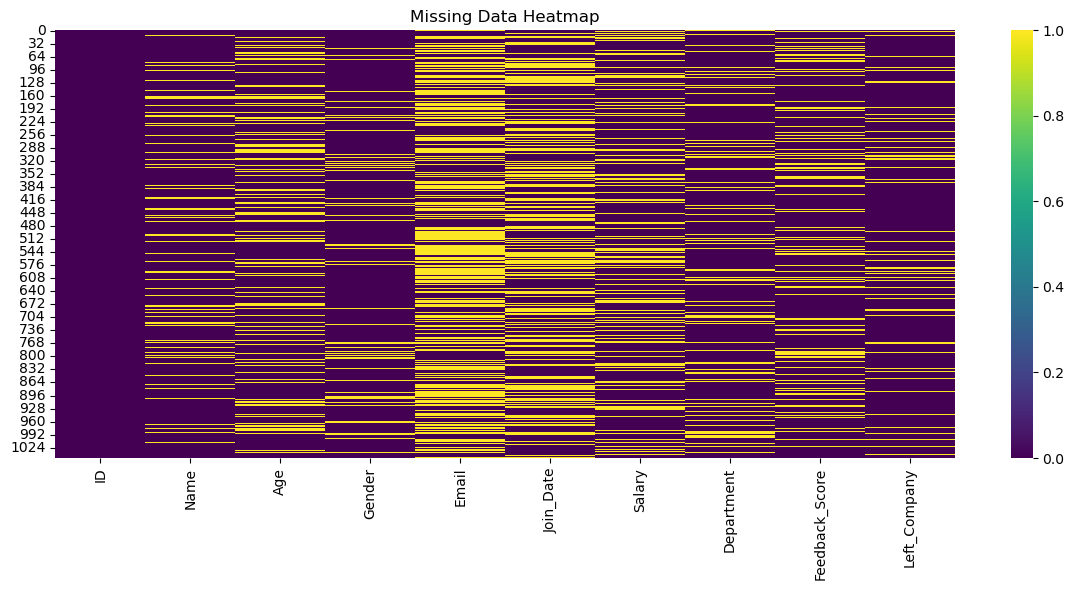

In [9]:
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=True, cmap='viridis')
plt.title('Missing Data Heatmap')
plt.tight_layout()
plt.show()

In [13]:
# Remove exact duplicates
df = df.drop_duplicates()   #you have to assign to a variable because drop_duplicates() return another dataframe
df.shape

(1001, 10)

In [14]:
df['Gender'].unique()

<StringArray>
['f', 'FEMALE', 'F', 'male', 'm', 'M', nan]
Length: 7, dtype: str

In [15]:
df['Gender'] = df['Gender'].str.lower().str.strip()
df['Gender'] = df['Gender'].replace({'f': 'female', 'm': 'male'})
df['Gender']

0       female
1       female
2       female
3         male
4         male
         ...  
1044      male
1045       NaN
1046    female
1047       NaN
1049      male
Name: Gender, Length: 1001, dtype: str

In [16]:
df['Gender'].unique()

<StringArray>
['female', 'male', nan]
Length: 3, dtype: str

In [17]:
df['Department'].unique()

<StringArray>
[nan, 'hr', 'FIN', 'ENG', 'Engineering', 'Finance', 'HR']
Length: 7, dtype: str

In [19]:
df['Department'] = df['Department'].str.upper().str.strip()  #strip for invisible spacing error
df['Department'] = df['Department'].replace({'HR': 'Human Resources', 'ENG': 'Engineering', 'FIN': 'Finance'})
df['Department']

0                   NaN
1                   NaN
2       HUMAN RESOURCES
3               FINANCE
4                   NaN
             ...       
1044        ENGINEERING
1045            FINANCE
1046        ENGINEERING
1047        ENGINEERING
1049            FINANCE
Name: Department, Length: 1001, dtype: str

In [20]:
df['Left_Company'].unique()

<StringArray>
['N', 'No', nan, '0', 'Y', '1', 'Yes']
Length: 7, dtype: str

In [24]:
df['Left_Company'] = df['Left_Company'].astype(str).str.lower().str.strip()  #astype(str) converts to string
df['Left_Company'] = df['Left_Company'].replace({'yes': 1, 'y': 1, '1': 1, 'no': 0, 'n': 0, '0': 0})
df['Left_Company'] = df['Left_Company'].astype('float')
df['Left_Company']

0       0.0
1       0.0
2       NaN
3       0.0
4       1.0
       ... 
1044    1.0
1045    NaN
1046    1.0
1047    0.0
1049    NaN
Name: Left_Company, Length: 1001, dtype: float64

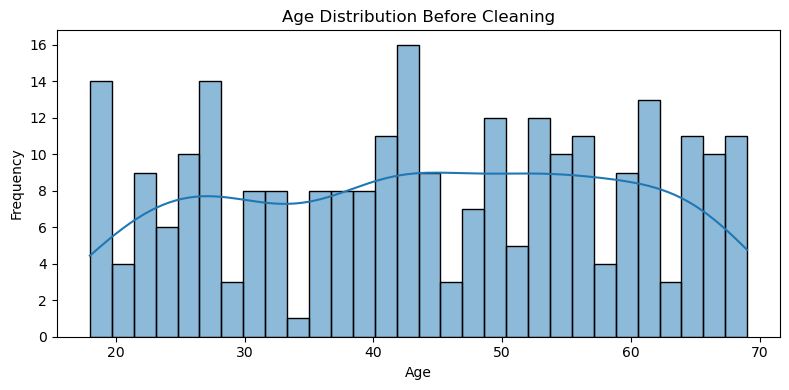

31.0
56.0
25.0
-6.5
93.5


In [33]:
# Plotting a histogram of Age to visualize distribution before cleaning
plt.figure(figsize=(8, 4))
sns.histplot(df['Age'], bins=30, kde=True)
plt.title("Age Distribution Before Cleaning")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Drop missing or clearly invalid ages temporarily to compute IQR
valid_ages = df['Age'].dropna()
valid_ages = valid_ages[valid_ages.between(0, 100)]  # quick fix to ignore impossible values

# Calculate IQR
Q1 = valid_ages.quantile(0.25)
Q3 = valid_ages.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Print IQR info
print (Q1)
print (Q3)
print (IQR)
print (lower_bound)
print (upper_bound)


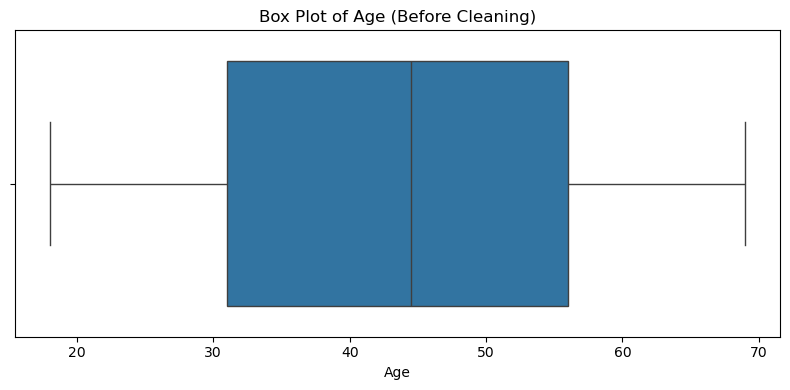

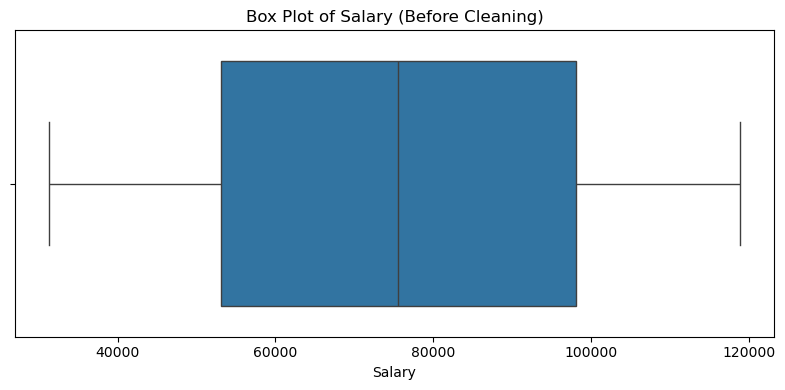

((np.float64(31.0),
  np.float64(56.0),
  np.float64(25.0),
  np.float64(-6.5),
  np.float64(93.5)),
 (np.float64(53127.5),
  np.float64(98143.0),
  np.float64(45015.5),
  np.float64(-14395.75),
  np.float64(165666.25)))

In [31]:
# Create box plot for Age
plt.figure(figsize=(8, 4))
sns.boxplot(x=valid_ages)
plt.title("Box Plot of Age (Before Cleaning)")
plt.xlabel("Age")
plt.tight_layout()
plt.show()

# Prepare Salary column for IQR analysis (remove clearly invalid entries)
valid_salaries = df['Salary'].dropna()
valid_salaries = valid_salaries[valid_salaries.between(10000, 200000)]  # realistic range

# Calculate IQR for Salary
Q1_salary = valid_salaries.quantile(0.25)
Q3_salary = valid_salaries.quantile(0.75)
IQR_salary = Q3_salary - Q1_salary
lower_salary = Q1_salary - 1.5 * IQR_salary
upper_salary = Q3_salary + 1.5 * IQR_salary

# Box plot for Salary
plt.figure(figsize=(8, 4))
sns.boxplot(x=valid_salaries)
plt.title("Box Plot of Salary (Before Cleaning)")
plt.xlabel("Salary")
plt.tight_layout()
plt.show()

# Return IQR details for both columns
(Q1, Q3, IQR, lower_bound, upper_bound), (Q1_salary, Q3_salary, IQR_salary, lower_salary, upper_salary)


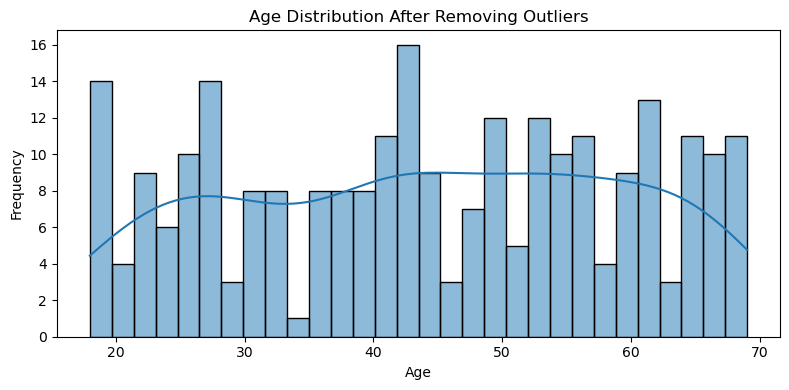

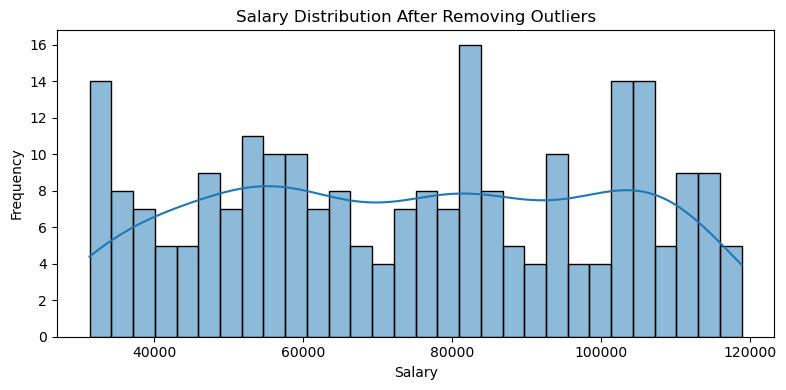

Age       743
Salary    762
dtype: int64

In [34]:
# Remove outliers in Age based on IQR bounds
df['Age'] = df['Age'].apply(lambda x: np.nan if pd.isna(x) or x < 0 or x > 90 else x)

# Remove outliers in Salary based on IQR bounds
df['Salary'] = df['Salary'].apply(lambda x: np.nan if pd.isna(x) or x < 10000 or x > 165666.25 else x)

# Visualize cleaned Age distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['Age'].dropna(), bins=30, kde=True)
plt.title("Age Distribution After Removing Outliers")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Visualize cleaned Salary distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['Salary'].dropna(), bins=30, kde=True)
plt.title("Salary Distribution After Removing Outliers")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Show how many rows were affected
df[['Age', 'Salary']].isnull().sum()


In [35]:
df['Join_Date'] = pd.to_datetime(df['Join_Date'], errors='coerce')


In [36]:
df['Email'] = df['Email'].fillna('').str.strip()
df['Email_Valid'] = df['Email'].str.contains(r'^[\w\.-]+@[\w\.-]+\.\w+$')
df.loc[~df['Email_Valid'], 'Email'] = np.nan  # Invalidate incorrect formats
df.drop(columns=['Email_Valid'], inplace=True)

In [38]:
df['Name'] = df['Name'].fillna('Unknown')
df['Department'] = df['Department'].fillna('Unknown')
df['Gender'] = df['Gender'].fillna('unknown')

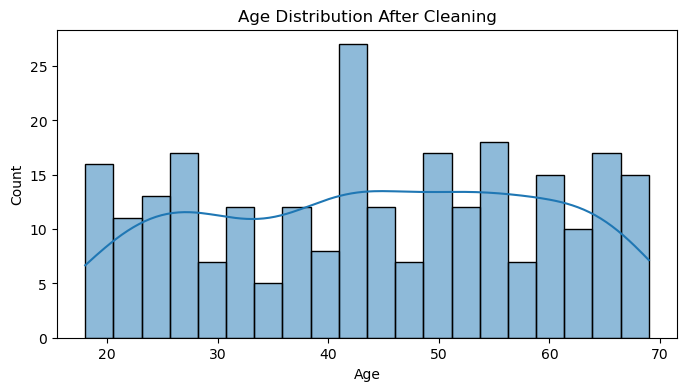

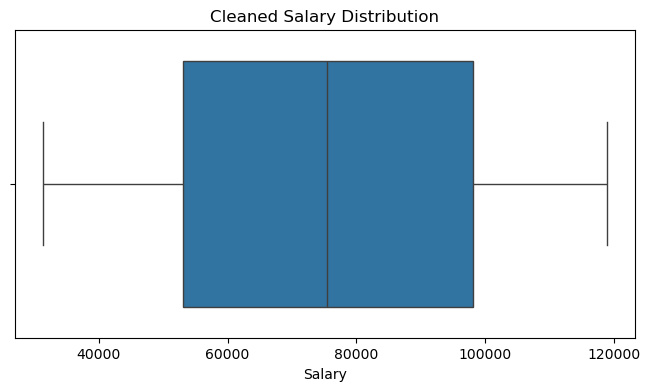

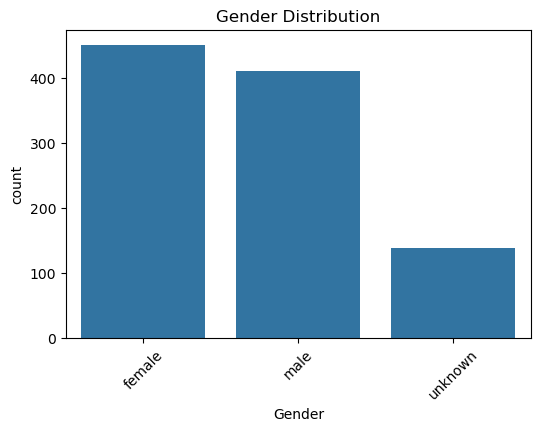

In [39]:
# Age distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['Age'], bins=20, kde=True)
plt.title("Age Distribution After Cleaning")
plt.show()

# Salary boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Salary'])
plt.title("Cleaned Salary Distribution")
plt.show()

# Gender counts
plt.figure(figsize=(6, 4))
sns.countplot(x='Gender', data=df)
plt.title("Gender Distribution")
plt.xticks(rotation=45)
plt.show()


In [40]:
df.info()
df.describe(include='all')

<class 'pandas.DataFrame'>
Index: 1001 entries, 0 to 1049
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   ID              1001 non-null   int64         
 1   Name            1001 non-null   str           
 2   Age             258 non-null    float64       
 3   Gender          1001 non-null   str           
 4   Email           261 non-null    str           
 5   Join_Date       398 non-null    datetime64[us]
 6   Salary          239 non-null    float64       
 7   Department      1001 non-null   str           
 8   Feedback_Score  764 non-null    float64       
 9   Left_Company    874 non-null    float64       
dtypes: datetime64[us](1), float64(4), int64(1), str(4)
memory usage: 70.4 KB


,ID,Name,Age,Gender,Email,Join_Date,Salary,Department,Feedback_Score,Left_Company
count,1001.000000,1001,258.000000,1001,261,398,239.000000,1001,764.000000,874.000000
unique,NaN,7,NaN,3,149,NaN,NaN,4,NaN,NaN
top,NaN,Unknown,NaN,female,user93@example.com,NaN,NaN,HUMAN RESOURCES,NaN,NaN
freq,NaN,153,NaN,451,5,NaN,NaN,287,NaN,NaN
mean,500.439560,NaN,44.124031,NaN,NaN,2020-09-19 13:34:04.221105,74574.912134,NaN,4.224607,0.518307
min,1.000000,NaN,18.000000,NaN,NaN,2020-05-30 00:00:00,31342.000000,NaN,0.000000,0.000000
25%,251.000000,NaN,31.000000,NaN,NaN,2020-05-30 00:00:00,53127.500000,NaN,0.000000,0.000000
50%,500.000000,NaN,44.500000,NaN,NaN,2021-01-01 00:00:00,75500.000000,NaN,3.000000,1.000000
75%,750.000000,NaN,56.000000,NaN,NaN,2021-01-01 00:00:00,98143.000000,NaN,10.000000,1.000000
max,1000.000000,NaN,69.000000,NaN,NaN,2024-03-15 00:00:00,118861.000000,NaN,10.000000,1.000000


In [43]:
# 1. Fill missing Age with median
df['Age'] = df['Age'].fillna(df['Age'].median())

# 2. Fill missing Salary with department-wise median
df['Salary'] = df.groupby('Department')['Salary'].transform(lambda x: x.fillna(x.median()))

# 3. Option B: Drop email column if not needed (This line was fine!)
df.drop(columns=['Email'], inplace=True, errors='ignore')

# 4. Fill Join_Date with a placeholder date
df['Join_Date'] = df['Join_Date'].fillna(pd.Timestamp('2000-01-01'))

# 5. Fill Feedback_Score with median
df['Feedback_Score'] = df['Feedback_Score'].fillna(df['Feedback_Score'].median())

# 6. Fill Left_Company with most frequent value
df['Left_Company'] = df['Left_Company'].fillna(df['Left_Company'].mode()[0])

# Optional: Verify all nulls are gone
print("Missing values after cleaning:\n")
print(df.isnull().sum())

Missing values after cleaning:

ID                0
Name              0
Age               0
Gender            0
Join_Date         0
Salary            0
Department        0
Feedback_Score    0
Left_Company      0
dtype: int64
